In [1]:

import pandas as pd

url = "https://cecgis-caenergy.opendata.arcgis.com/api/download/v1/items/cc646bb5050d4276a7283612c7a24228/csv?layers=0"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
df.head()


Dataset loaded successfully!
Number of rows and columns: (17186, 12)

Column names:
['X', 'Y', 'OBJECTID', 'Latitude', 'Longitude', 'ID', 'City', 'ZIP', 'L1_evse', 'L2_evse', 'DCFC', 'Charger_Type']

First 5 rows:


,X,Y,OBJECTID,Latitude,Longitude,ID,City,ZIP,L1_evse,L2_evse,DCFC,Charger_Type
0,159607.8458,-440215.6397,1,34.040539,-118.271387,1523,Los Angeles,90015.0,0,7,0,Level 2 only
1,258217.0919,-564405.2785,2,32.899470,-117.243000,6355,La Jolla,92037.0,0,1,0,Level 2 only
2,141096.9561,-420437.1924,3,34.221665,-118.468371,6405,Sepulveda,91343.0,0,2,0,Level 2 only
3,234985.6350,-453010.4592,4,33.909914,-117.459053,6425,Riverside,92503.0,0,4,0,Level 2 only
4,170848.9730,-428122.2716,5,34.147620,-118.147111,6505,Pasadena,91103.0,0,16,0,Level 2 only


In [2]:

# Step 2: Check the dataset

print("Dataset size:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Dataset size:
(17186, 12)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17186 entries, 0 to 17185
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   X             17186 non-null  float64
 1   Y             17186 non-null  float64
 2   OBJECTID      17186 non-null  int64  
 3   Latitude      17186 non-null  float64
 4   Longitude     17186 non-null  float64
 5   ID            17186 non-null  int64  
 6   City          17186 non-null  object 
 7   ZIP           17185 non-null  float64
 8   L1_evse       17186 non-null  int64  
 9   L2_evse       17186 non-null  int64  
 10  DCFC          17186 non-null  int64  
 11  Charger_Type  17186 non-null  object 
dtypes: float64(5), int64(5), object(2)
memory usage: 1.6+ MB

Missing values in each column:
X               0
Y               0
OBJECTID        0
Latitude        0
Longitude       0
ID              0
City            0
ZIP             1
L1_e

In [3]:

# Step 3: Clean the data

# Make a copy so the original data stays unchanged
clean_df = df.copy()

# Check for missing ZIP codes
print("Missing ZIP codes before cleaning:")
print(clean_df["ZIP"].isnull().sum())

# Fill the one missing ZIP code with "Unknown"
clean_df["ZIP"] = clean_df["ZIP"].fillna("Unknown")

# Check for negative charger counts
charger_columns = ["L1_evse", "L2_evse", "DCFC"]

print("\nNegative charger counts:")
print((clean_df[charger_columns] < 0).sum())

# Create a column for the total chargers at each location
clean_df["Total_Chargers"] = clean_df[charger_columns].sum(axis=1)

# Check the cleaned dataset
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nFirst 5 rows after cleaning:")
clean_df.head()


Missing ZIP codes before cleaning:
1

Negative charger counts:
L1_evse    0
L2_evse    0
DCFC       0
dtype: int64

Missing values after cleaning:
X                 0
Y                 0
OBJECTID          0
Latitude          0
Longitude         0
ID                0
City              0
ZIP               0
L1_evse           0
L2_evse           0
DCFC              0
Charger_Type      0
Total_Chargers    0
dtype: int64

First 5 rows after cleaning:


,X,Y,OBJECTID,Latitude,Longitude,ID,City,ZIP,L1_evse,L2_evse,DCFC,Charger_Type,Total_Chargers
0,159607.8458,-440215.6397,1,34.040539,-118.271387,1523,Los Angeles,90015.0,0,7,0,Level 2 only,7
1,258217.0919,-564405.2785,2,32.899470,-117.243000,6355,La Jolla,92037.0,0,1,0,Level 2 only,1
2,141096.9561,-420437.1924,3,34.221665,-118.468371,6405,Sepulveda,91343.0,0,2,0,Level 2 only,2
3,234985.6350,-453010.4592,4,33.909914,-117.459053,6425,Riverside,92503.0,0,4,0,Level 2 only,4
4,170848.9730,-428122.2716,5,34.147620,-118.147111,6505,Pasadena,91103.0,0,16,0,Level 2 only,16


In [4]:

# Step 4: Explore chargers by city

# Count the number of listed charging locations in each city
locations_by_city = clean_df["City"].value_counts()

print("Top 10 cities by number of charging locations:")
print(locations_by_city.head(10))

# Add up the total chargers reported in each city
chargers_by_city = (
    clean_df.groupby("City")["Total_Chargers"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop 10 cities by total number of chargers:")
print(chargers_by_city.head(10))

print("\nBottom 10 cities by total number of chargers:")
print(chargers_by_city.tail(10))


Top 10 cities by number of charging locations:
City
Los Angeles      1550
San Diego         718
Irvine            670
San Jose          594
San Francisco     535
Santa Clara       371
Sacramento        362
Menlo Park        304
Anaheim           229
Long Beach        205
Name: count, dtype: int64

Top 10 cities by total number of chargers:
City
Los Angeles      4122
San Diego        2373
San Jose         1935
Irvine           1474
San Francisco    1351
Sacramento       1186
Santa Clara       845
Anaheim           637
Santa Monica      614
Menlo Park        613
Name: Total_Chargers, dtype: int64

Bottom 10 cities by total number of chargers:
City
South El Monte             1
Essex                      1
Unit B City of Industry    1
Cardova                    1
Chatsworth Lake Manor      1
Coto De Caza               1
Bell Gardens               1
Bradley                    1
Bolinas                    1
Antelope                   1
Name: Total_Chargers, dtype: int64


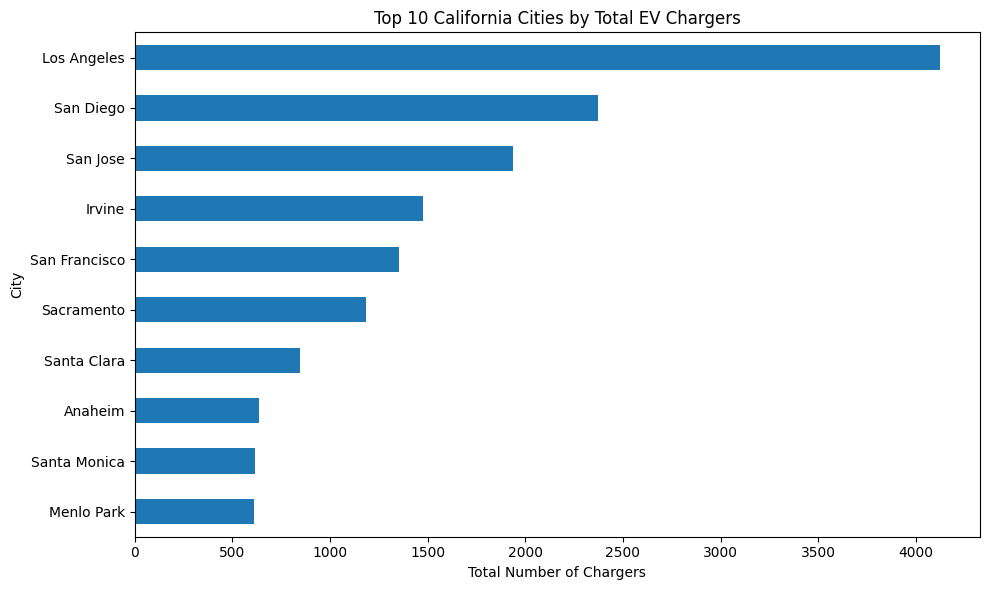

In [5]:

import matplotlib.pyplot as plt

# Get the top 10 cities by total chargers
top_10 = chargers_by_city.head(10).sort_values()

# Create the bar chart
plt.figure(figsize=(10, 6))
top_10.plot(kind="barh")

plt.title("Top 10 California Cities by Total EV Chargers")
plt.xlabel("Total Number of Chargers")
plt.ylabel("City")
plt.tight_layout()

plt.show()


In [6]:
plt.savefig("chart1_top10_ev_chargers.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [7]:

# Add up each type of charger across the dataset

charger_totals = clean_df[["L1_evse", "L2_evse", "DCFC"]].sum()

print("Total chargers by type:")
print(charger_totals)


Total chargers by type:
L1_evse       60
L2_evse    37151
DCFC       13587
dtype: int64


In [8]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

In [9]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

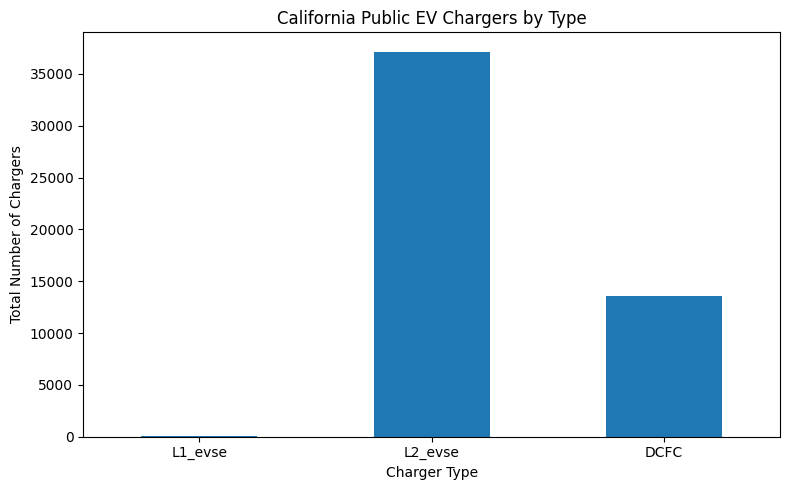

In [10]:

import matplotlib.pyplot as plt

charger_totals = clean_df[["L1_evse", "L2_evse", "DCFC"]].sum()

plt.figure(figsize=(8, 5))
charger_totals.plot(kind="bar")

plt.title("California Public EV Chargers by Type")
plt.xlabel("Charger Type")
plt.ylabel("Total Number of Chargers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("chart2_chargers_by_type.png", dpi=300, bbox_inches="tight")
plt.show()


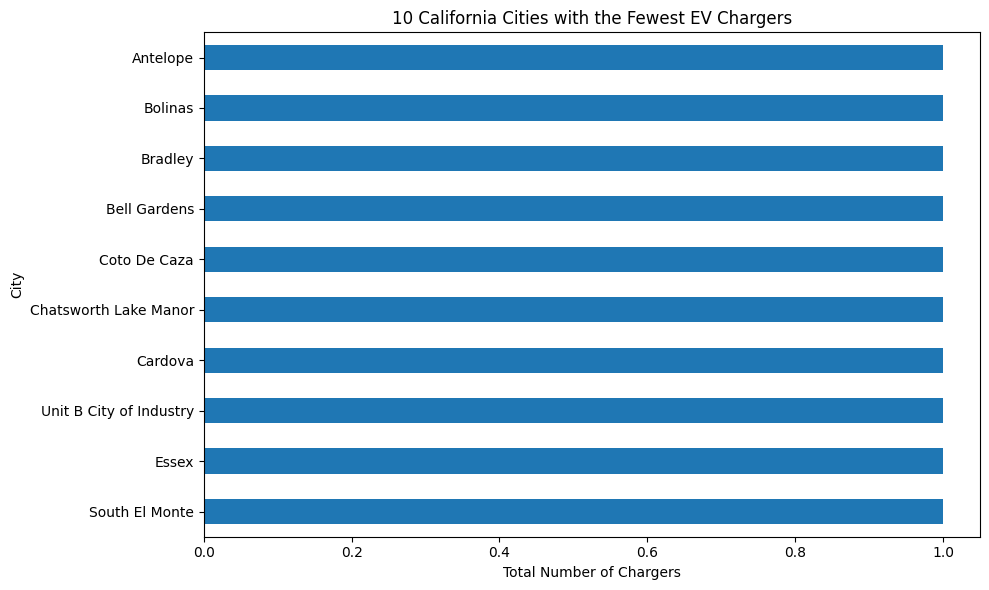

In [11]:

import matplotlib.pyplot as plt

bottom_10 = chargers_by_city.tail(10).sort_values()

plt.figure(figsize=(10, 6))
bottom_10.plot(kind="barh")

plt.title("10 California Cities with the Fewest EV Chargers")
plt.xlabel("Total Number of Chargers")
plt.ylabel("City")
plt.tight_layout()

plt.savefig("chart3_fewest_ev_chargers.png", dpi=300, bbox_inches="tight")
plt.show()


In [12]:

clean_df.to_csv("california_ev_chargers_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Number of rows:", len(clean_df))
print("Number of columns:", len(clean_df.columns))


Cleaned dataset saved successfully!
Number of rows: 17186
Number of columns: 13


In [13]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

 California Public EV Chargers

My project looks at which California cities have the most and fewest public EV chargers in the dataset.

1. Cities with the most chargers

Los Angeles had the most charging locations, with 1,550 locations and 4,122 chargers. San Diego was second, with 718 locations and 2,373 chargers. San Jose had 1,935 chargers, followed by Irvine with 1,474 and San Francisco with 1,351

 2. Charger types

The dataset contained 60 Level 1 chargers, 37,151 Level 2 chargers, and 13,587 DC fast chargers. Level 2 chargers were the most common type in the dataset.

3. Cities with the fewest chargers

The 10 cities at the bottom of the results each had only one charger recorded. This shows that the number of chargers varies across cities in the dataset. However, it does not necessarily mean these cities have the worst charging access, because the dataset may not represent every available charger.

The Conclusion

Based on this dataset, Los Angeles had the most public EV chargers, while several cities had only one charger recorded. Level 2 chargers were much more common than Level 1 chargers. These results help show how public EV chargers are distributed across the cities represented in the dataset.